# EPR simulations with `epreasy`

The simulators of [EasySpin](https://easyspin.org) in Python, on the
foundation described in [EPR spin systems with `epreasy`](epreasy.ipynb):
`pepper` for powders and crystals, `garlic` for isotropic solutions, `esfit`
for least-squares fitting, `salt` for ENDOR, `curry` for magnetometry and
`chili` for the slow-motion regime and `saffron` for pulse EPR (ESEEM,
HYSCORE, Mims ENDOR). Every function keeps EasySpin's
interface (dicts with EasySpin's field names, mT and MHz, 1-based spin
numbers) and is verified against EasySpin 6.0.15; what differs is listed in
[Coming from EasySpin](coming-from-easyspin.ipynb). The companion notebook is
[`notebooks/epreasy-simulators.ipynb`](epreasy-simulators.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/epreasy-simulators.ipynb)).

*Generated from [`docs/epreasy-simulators.md`](../epreasy-simulators.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Powder and crystal spectra: `pepper`](#Powder-and-crystal-spectra:-pepper)
2. [Solution spectra: `garlic`](#Solution-spectra:-garlic)
3. [Fitting spectra: `esfit`](#Fitting-spectra:-esfit)
4. [ENDOR: `endorfrq` and `salt`](#ENDOR:-endorfrq-and-salt)
5. [Magnetometry: `curry`](#Magnetometry:-curry)
6. [Slow motion: `chili`](#Slow-motion:-chili)
7. [Pulse EPR: `saffron`](#Pulse-EPR:-saffron)

The examples share one spin system, the nitroxide of the foundation guide:

In [1]:
import numpy as np

import epreasy as es

nitroxide = {"g": [2.0088, 2.0061, 2.0027], "Nucs": "14N", "A": [16, 16, 86]}

## Powder and crystal spectra: `pepper`

`pepper(spin_system, exp, opt)` is EasySpin's cw EPR simulator for solids,
and it runs the pipeline of the foundation guide the way EasySpin does. The point group of the
Hamiltonian (`hamsymm`) picks the region of the sphere to integrate over and
`sphgrid` the knots on it; `resfields` (the default `Opt["Method"] =
"matrix"`), the hybrid method, perturbation theory (`"perturb1"`,
`"perturb2"`, for S = 1/2 with the nuclei to first or second order) or the
eigenfield method (`"eig"`, a stick spectrum by brute force) give the
resonance positions, intensities and strain widths on the knots; the
positions are interpolated onto a finer grid (`Opt["GridSize"] = [knots,
refinement]`, cubic splines along the meridians and across the octant) and
projected from the triangles of the grid onto the field axis, which gives
the powder pattern of the resonance positions without binning artefacts; the
pattern is convolved with the isotropic line (`lwpp` or `lw`, Gaussian and
Lorentzian parts), differentiated to `Exp["Harmonic"]` and, with
`Exp["ModAmp"]`, pseudo-modulated. When the width is orientation-dependent
(strains), each resonance is instead added as a line of its own width, from
a template, with the kernel `lisum1i`. The result is a named tuple
`Spectrum(x, spec, info)`; `info["Transitions"]` lists the level pairs. Set
`Opt["FuzzLevel"] = 0` for reproducible numbers.

In [2]:
powder = {**nitroxide, "lwpp": 0.3}
exp = {"mwFreq": 9.5, "Range": [330, 350], "nPoints": 1024}
matrix = es.pepper(powder, exp, {"FuzzLevel": 0})
perturb = es.pepper(powder, exp, {"FuzzLevel": 0, "Method": "perturb2"})
print("transitions:", matrix.info["Transitions"].tolist(), " orientations:", matrix.info["nOrientations"])
print("matrix and second-order perturbation theory differ by", f"{np.abs(matrix.spec - perturb.spec).max() / np.abs(matrix.spec).max():.1%}")

transitions: [[1, 5], [1, 6], [2, 4], [2, 5], [2, 6], [3, 4], [3, 5]]  orientations: 190
matrix and second-order perturbation theory differ by 1.4%


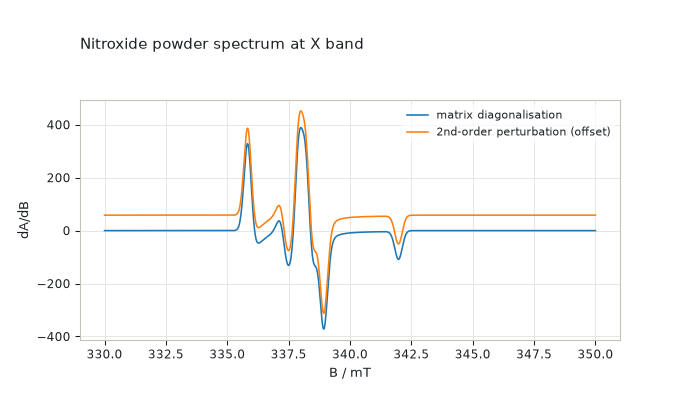

In [3]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=matrix.x, y=matrix.spec, mode="lines", name="matrix diagonalisation"))
fig.add_trace(go.Scatter(x=perturb.x, y=perturb.spec + 0.15 * matrix.spec.max(), mode="lines", name="2nd-order perturbation (offset)"))
fig.update_layout(title="Nitroxide powder spectrum at X band", xaxis_title="B / mT", yaxis_title="dA/dB", width=700, height=420)
fig

The methods are chosen as in EasySpin: for Cu(II) with four 14N (648
states) full diagonalisation takes a minute, the hybrid method and
perturbation theory a fraction of a second, and `pepper` selects the grid
and the kernels by itself. Strains make the widths orientation-dependent
and switch `pepper` to the summation path; `Opt["separate"] =
"transitions"` returns one spectrum per transition; `Exp["SampleFrame"]`
rows with `Exp["MolFrame"]` make it a crystal, summed over the orientations
(`Opt["separate"] = "orientations"` keeps them apart), and `Exp["Harmonic"]
= 0` gives the absorption spectrum:

In [4]:
cu4n = {"S": 1 / 2, "g": [2.05, 2.05, 2.2], "Nucs": "63Cu,14N,14N,14N,14N", "A": [[50, 50, 500]] + [[40, 40, 40]] * 4, "lwpp": 1}
cu_exp = {"mwFreq": 9.5, "Range": [260, 360]}
hybrid = es.pepper(cu4n, cu_exp, {"FuzzLevel": 0, "Method": "hybrid", "HybridCoreNuclei": [1]})
second = es.pepper(cu4n, cu_exp, {"FuzzLevel": 0, "Method": "perturb2"})
print("Cu(II) with four 14N: hybrid and perturb2 differ by", f"{np.abs(hybrid.spec - second.spec).max() / np.abs(hybrid.spec).max():.1%}")
strained = es.pepper({**nitroxide, "HStrain": [20, 20, 60]}, exp, {"FuzzLevel": 0})
per_transition = es.pepper(powder, exp, {"FuzzLevel": 0, "separate": "transitions"})
crystal = es.pepper(powder, {**exp, "SampleFrame": [[0, 0, 0], [0.3, 1.1, 0.7]], "MolFrame": [0, 0, 0]}, {"FuzzLevel": 0, "separate": "orientations"})
absorption = es.pepper(powder, {**exp, "Harmonic": 0}, {"FuzzLevel": 0})
print("strained spectrum, per-transition spectra, crystal spectra:", strained.spec.shape, per_transition.spec.shape, crystal.spec.shape)
print("absorption area:", (absorption.spec.sum() * (absorption.x[1] - absorption.x[0])).round(3), " first derivative sums to", matrix.spec.sum().round(9))

Cu(II) with four 14N: hybrid and perturb2 differ by 7.3%
strained spectrum, per-transition spectra, crystal spectra: (1024,) (7, 1024) (2, 1024)
absorption area: 554.171  first derivative sums to -0.0


## Solution spectra: `garlic`

`garlic(spin_system, exp, opt)` simulates isotropic cw spectra of S = 1/2
systems: the line positions come from the Breit-Rabi formula (exact for one
nucleus, iterated for several) or from perturbation theory to the order in
`Opt["Method"]` (`"perturb1"` to `"perturb5"`), equivalent nuclei
(`Sys["n"]`) are coupled with `equivcouple`, and each line gets the
isotropic width (`lwpp` or `lw`, Gaussian and Lorentzian) plus, when
`Sys["tcorr"]` (or `logtcorr`) is given, the fast-motion Lorentzian width of
its mI combination from the anisotropies of g, A and Q (`fastmotion`, the
Kivelson A + B mI + C mI² expression with the spectral densities of the
rotational correlation time). `Exp["Field"]` with `mwRange` gives a
frequency sweep. The lines are accumulated by binning (the default),
summed from a template, or evaluated explicitly (`Opt["AccumMethod"]`).

In [5]:
solution = {"g": [2.0088, 2.0064, 2.0027], "Nucs": "14N", "A": es.unitconvert(np.array([7.59, 5.95, 31.76]) / 10, "mT->MHz"), "lwpp": 0.02}
rigid = es.garlic({**solution, "tcorr": 1e-11}, {"mwFreq": 9.5, "Range": [336, 341], "nPoints": 2048})
slow = es.garlic({**solution, "tcorr": 1e-9}, {"mwFreq": 9.5, "Range": [336, 341], "nPoints": 2048})
widths, mI = es.fastmotion(solution, 340, 1e-9)
print("fast-motion widths (mT) for mI =", mI.ravel().tolist(), ":", widths.round(4))
print("line positions (mT):", np.sort(slow.info["resfields"]).round(3))

fast-motion widths (mT) for mI = [-1.0, 0.0, 1.0] : [0.4216 0.1725 0.168 ]
line positions (mT): [336.857 338.361 339.871]


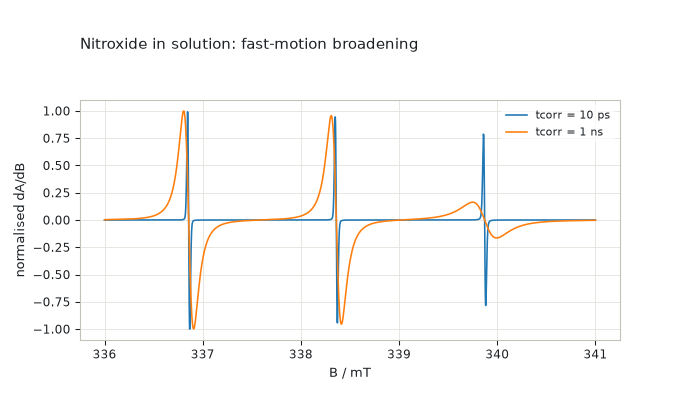

In [6]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=rigid.x, y=rigid.spec / np.abs(rigid.spec).max(), mode="lines", name="tcorr = 10 ps"))
fig.add_trace(go.Scatter(x=slow.x, y=slow.spec / np.abs(slow.spec).max(), mode="lines", name="tcorr = 1 ns"))
fig.update_layout(title="Nitroxide in solution: fast-motion broadening", xaxis_title="B / mT", yaxis_title="normalised dA/dB", width=700, height=420)
fig

In [7]:
protons = es.garlic({"g": 2.0, "Nucs": "1H,1H", "n": [3, 2], "A": [30, 12], "lw": [0.2, 0]}, {"mwFreq": 9.5, "Range": [325, 352], "Harmonic": 0})
print("CH3-CH2 pattern:", protons.info["resfields"].size, "lines, the strongest at", protons.x[protons.spec.argmax()].round(2), "mT")
sweep = es.garlic({"g": 2.006, "Nucs": "14N", "A": 47, "lw": 0.1}, {"Field": 340, "mwRange": [9.4, 9.6]})
print("frequency sweep at 340 mT: lines at", np.sort(sweep.info["resfields"]).round(4), "GHz")

CH3-CH2 pattern: 24 lines, the strongest at 339.91 mT
frequency sweep at 340 mT: lines at [9.4991 9.5462 9.5931] GHz


## Fitting spectra: `esfit`

`esfit(data, fcn, p0, vary)` or `esfit(data, fcn, p0, lb, ub)`, with an
options dict last, fits a model to data by least squares, as EasySpin's
`esfit` does without its window. For `pepper` and `garlic` the parameters
are the input dicts themselves: `p0 = [sys, exp]` (or `[sys, exp, opt]`) and
`vary` is a list of dicts of the same shape whose numeric fields say by how
much each value may move (`[{"g": [0.02, 0.02], "lw": 0.5}]`; a zero fixes
the value); `lb`/`ub` give bounds instead. Any other callable `fcn(p)` takes
a parameter vector and returns the model data, or a list of arrays for a
global fit of several data sets. `Opt["Method"]` names the algorithm
(`simplex`, `levmar`, `montecarlo`, `genetic`, `grid`, `swarm`, or
`lsqnonlin` for SciPy's bounded least squares) and the target the residuals
are taken from (`fcn`, `int`, `dint`, `diff`, `fft`; the integral is the
default for `pepper` and `garlic`, whose derivative spectra it makes
smoother to fit). `AutoScale` fits a scale factor (`lsq`, the default for
the simulators), `BaseLine` a polynomial baseline, `Mask` leaves points
out, `weight` balances data sets. The result carries the fitted parameters
with their standard deviations, 95 % confidence intervals, covariance and
correlation matrices (from a Romberg-extrapolated Jacobian and a
heteroscedasticity-consistent covariance estimate, as in EasySpin), the
fitted data, scale and baseline, the residuals and the goodness-of-fit
numbers; `Verbosity = 1` prints the report, `2` adds the iterations.

In [8]:
truth = {"g": [2.0, 2.1], "lw": 3}
exp = {"mwFreq": 9.5, "Range": [300, 360], "nPoints": 300}
measured = es.addnoise(es.pepper(truth, exp, {"FuzzLevel": 0}).spec, 40, "n", rng=1)
start = [{"g": [2.005, 2.095], "lw": 2.5}, exp, {"FuzzLevel": 0}]  # within a line width of the truth
result = es.esfit(measured, es.pepper, start, [{"g": [0.02, 0.02], "lw": 1.5}], {"Verbosity": 0})
for name, value, std in zip(result.pnames, result.pfit, result.pstd, strict=True):
    print(f"{name:14s} {value:9.5f} +- {std:.5f}")
print("rmsd", round(result.rmsd, 3), " scale", result.scale.round(4), " fitted system:", result.argsfit[0])

arg1.g(1,1)      2.00006 +- 0.00011
arg1.g(1,2)      2.10037 +- 0.00084
arg1.lw          3.03899 +- 0.03561
rmsd 0.936  scale [1.0103]  fitted system: {'g': array([2.00006309, 2.10037472]), 'lw': 3.038989078423012}


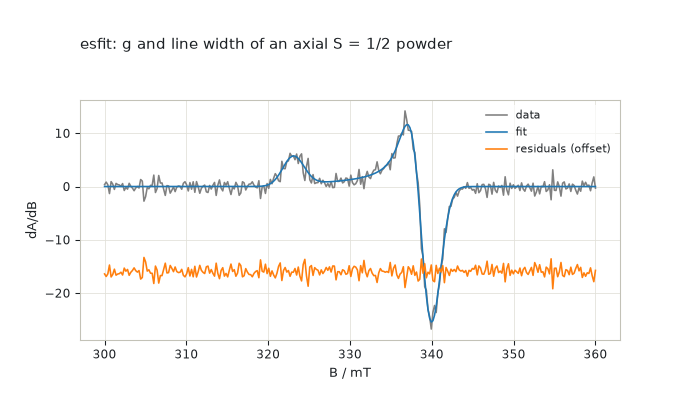

In [9]:
import plotly.graph_objects as go

B = np.linspace(300, 360, 300)
fig = go.Figure()
fig.add_trace(go.Scatter(x=B, y=measured, mode="lines", name="data", line={"color": "gray"}))
fig.add_trace(go.Scatter(x=B, y=result.fit, mode="lines", name="fit"))
fig.add_trace(go.Scatter(x=B, y=result.residuals - 0.6 * np.abs(measured).max(), mode="lines", name="residuals (offset)"))
fig.update_layout(title="esfit: g and line width of an axial S = 1/2 powder", xaxis_title="B / mT", yaxis_title="dA/dB", width=700, height=420)
fig

The algorithms are also available on their own, for any function:
`esfit_simplex` and `esfit_levmar` start from a point, `esfit_montecarlo`,
`esfit_genetic`, `esfit_grid` and `esfit_swarm` search the bounds. With the
helpers `rescaledata`, `basecorr`, `deriv` and `addnoise`, data can be
prepared and compared as in EasySpin.

In [10]:
x = np.linspace(300, 400, 200)
model = lambda p: 5 * np.exp(-((x - p[0]) ** 2) / (2 * p[1] ** 2))  # noqa: E731
data = model([350, 7]) + 0.4 + 0.003 * (x - 300)  # with a sloping baseline
fit = es.esfit(data, model, [340, 5], [50, 20], {"Method": "levmar", "BaseLine": 1, "Verbosity": 0})
print("centre and width:", fit.pfit.round(4), " baseline type:", fit.baselinetype, " rmsd:", f"{fit.rmsd:.1e}")
xmin, info = es.esfit_simplex(lambda p: (p[0] - 1) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2, [-1, 1.5], [-2, -2], [2, 2])
print("Rosenbrock minimum by simplex:", xmin.round(3), "after", info["nEvals"], "evaluations")
corrected, baseline = es.basecorr(data, 1, 1, region=np.abs(x - 350) > 35)  # fit the baseline beside the line
print("baseline removed:", np.abs(corrected - model([350, 7])).max() < 1e-4)

centre and width: [350.0001   7.0001]  baseline type: ['linear']  rmsd: 3.0e-05
Rosenbrock minimum by simplex: [1. 1.] after 166 evaluations
baseline removed: True


## ENDOR: `endorfrq` and `salt`

At a fixed field, the nuclear transitions of a spin system are the ENDOR
lines. `endorfrq(spin_system, exp, opt)` diagonalises the Hamiltonian at
`exp["Field"]` for each orientation, selects the NMR transitions by their
nuclear Zeeman transition rates on a coarse grid (`Opt["Threshold"]`,
`Opt["Nuclei"]`) and returns their frequencies (MHz) and intensities, with
the hyperfine enhancement (`Opt["Enhancement"] = "on"` adds the electron
Zeeman term to the detection operator), the orientation selection of a
finite microwave excitation (`exp["ExciteWidth"]` in MHz together with
`Sys["HStrain"]`: only orientations whose EPR transitions fall into the
excitation window contribute, and `info["Selectivity"]` says how strongly),
Boltzmann populations (`Temperature`) and pulse-ENDOR flip angles
(`exp["rf"]`). `endorfrq_perturb` gives the same frequencies by Iwasaki's
first- and second-order perturbation formulas, and `orisel` the
orientation-selection weights alone. `salt(spin_system, exp, opt)` turns
the resonances into the powder or crystal ENDOR spectrum with the grid,
interpolation, projection and convolution machinery of `pepper`
(`Sys["lwEndor"]` is the ENDOR line width, Gaussian and Lorentzian parts).

In [11]:
proton = {"S": 1.5, "D": 200, "Nucs": "1H", "A": [3, 5], "lwEndor": 0.2}
endor_exp = {"Field": 350, "mwFreq": 9.5, "Range": [5, 25]}
res = es.endorfrq(proton, {"Field": 350, "SampleFrame": [0.3, 1.1, 0.7]})
print("ENDOR lines of one orientation (MHz):", np.sort(res.pos.ravel()).round(3), " transitions:", res.trans.tolist())
matrix = es.salt(proton, endor_exp)
perturb = es.salt(proton, endor_exp, {"Method": "perturb2"})
print("matrix and perturbation spectra differ by", f"{np.abs(matrix.spec - perturb.spec).max() / matrix.spec.max():.1%}")

ENDOR lines of one orientation (MHz): [ 9.857 13.222 16.638 20.03 ]  transitions: [[5, 6], [3, 4], [1, 2], [7, 8]]
matrix and perturbation spectra differ by 0.3%


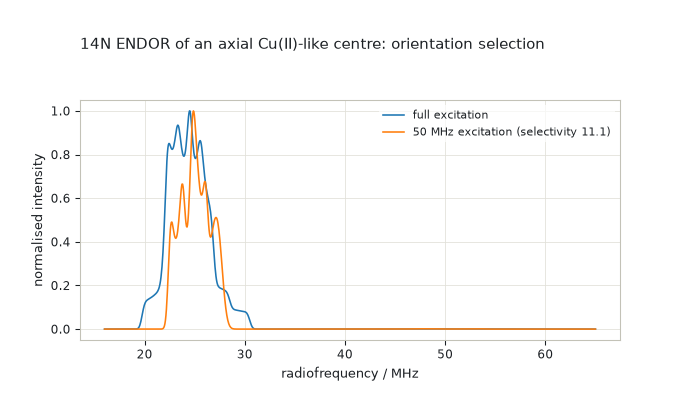

In [12]:
import plotly.graph_objects as go

nitrogen = {"Nucs": "14N", "g": [2.25, 2.25, 2], "A": [44, 49, 54], "Q": [0.84, 0.84, -1.68], "HStrain": [100, 100, 100], "lwEndor": 0.5}
full = es.salt(nitrogen, {"Range": [16, 65], "Field": 326.5, "mwFreq": 9.7, "nPoints": 1001})
selected = es.salt(nitrogen, {"Range": [16, 65], "Field": 326.5, "mwFreq": 9.7, "nPoints": 1001, "ExciteWidth": 50})
fig = go.Figure()
fig.add_trace(go.Scatter(x=full.x, y=full.spec / full.spec.max(), mode="lines", name="full excitation"))
fig.add_trace(go.Scatter(x=selected.x, y=selected.spec / selected.spec.max(), mode="lines", name=f"50 MHz excitation (selectivity {selected.info['Selectivity']:.1f})"))
fig.update_layout(title="14N ENDOR of an axial Cu(II)-like centre: orientation selection", xaxis_title="radiofrequency / MHz", yaxis_title="normalised intensity", width=700, height=420)
fig

## Magnetometry: `curry`

`curry(spin_system, exp, opt)` computes the magnetic moment along the
field and the static susceptibility for arrays of fields (`exp["Field"]`,
mT) and temperatures (`exp["Temperature"]`, K), as (nFields, nTemperatures)
arrays, averaged over a powder grid or for crystal orientations. By default
the moment is the thermal average of the magnetic-moment operator over the
eigenstates and the susceptibility its numerical field derivative
(`Opt["Method"] = "partitionfunction"` differentiates the log of the
partition function instead). `Opt["Output"]` picks the quantities: `mu`,
`mumol`, `muBM` (Bohr magnetons), `muvec`, `chi`, `chimol`, `chimolT`,
`1/chimol`, `mueff`, in SI or CGS-emu (`Opt["Units"]`); `Opt["Spins"]`
restricts the moment to some electron spins, `Sys["TIP"]` adds a
temperature-independent susceptibility.

In [13]:
dimer = {"S": [0.5, 0.5], "g": [2, 2], "ee": 2 * 4 * 30e3}  # antiferromagnetic exchange, J = -4 cm^-1 as ee = -2J
T = np.arange(1, 301.0)
chimolT = es.curry(dimer, {"Temperature": T, "Field": 100}, {"Output": "chimolT"})
curie = 2 * 0.5 * 1.5 * 4 * es.mu0 * es.bmagn**2 * es.avogadro / 3 / es.boltzm  # two uncoupled S = 1/2 at high temperature
print("chimol*T at 1 K and 300 K (m^3 K/mol):", chimolT.ravel()[[0, -1]].round(8), " two free spins:", round(curie, 8))
mu = es.curry({"S": 0.5, "g": 2.0}, {"Temperature": 2.0, "Field": [0, 2000, 5000, 10000]}, {"Output": "muBM"})
print("S = 1/2 magnetisation at 2 K follows tanh:", mu.ravel().round(4), np.tanh(es.bmagn * np.array([0, 2, 5, 10]) / (es.boltzm * 2.0)).round(4))

chimol*T at 1 K and 300 K (m^3 K/mol): [0.00e+00 9.34e-06]  two free spins: 9.43e-06
S = 1/2 magnetisation at 2 K follows tanh: [0.     0.5861 0.9328 0.9976] [0.     0.5861 0.9328 0.9976]


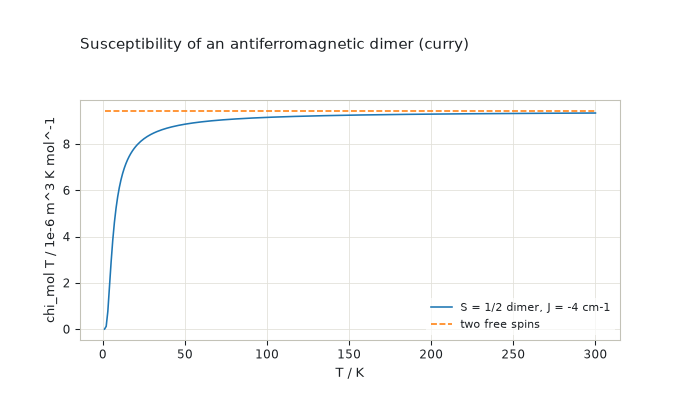

In [14]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=T, y=chimolT.ravel() * 1e6, mode="lines", name="S = 1/2 dimer, J = -4 cm-1"))
fig.add_trace(go.Scatter(x=[T[0], T[-1]], y=[curie * 1e6] * 2, mode="lines", line={"dash": "dash"}, name="two free spins"))
fig.update_layout(title="Susceptibility of an antiferromagnetic dimer (curry)", xaxis_title="T / K", yaxis_title="chi_mol T / 1e-6 m^3 K mol^-1", width=700, height=420)
fig

## Slow motion: `chili`

Between the rigid limit of `pepper` and the fast-motion limit of `garlic`
lies the slow-motion regime, where the rotational diffusion of the molecule
is neither frozen nor averaged on the time scale of the anisotropies.
`chili(spin_system, exp, opt)` solves the stochastic Liouville equation for
it, as EasySpin does: the spin density operator is expanded in the product
of the spin Liouville space with Wigner rotation functions (the
K-symmetrised `LjKKM` basis of the Freed programs, truncated by
`Opt["LLMK"] = [evenLmax, oddLmax, Mmax, Kmax]`), the Hamiltonian becomes a
sparse superoperator built from the rotational basis operators and 3j
symbols, Brownian diffusion (`Sys["tcorr"]`, `logtcorr`, `Diff` or
`logDiff`, isotropic, axial or rhombic) adds the diffusion superoperator,
and the spectrum is the resolvent of the result on the starting vector,
evaluated by Lanczos tridiagonalisation and a continued fraction
(`Opt["Solver"] = "L"`; `"\\"`, `"E"`, `"C"` and `"B"` solve, diagonalise
or iterate instead). An orientational potential (`Sys["Potential"]`, rows
`[L, M, K, lambda]`) restrains the motion, and `Opt["GridSize"]` averages
the director over a grid (MOMD); `Exp["SampleFrame"]` sets a single director
orientation and `Exp["Ordering"]` a partially ordered director distribution.
Field sweeps are computed from one Liouvillian at the centre field
(`Opt["FieldSweepMethod"] = "approxlin"`, the default) or point by point
(`"explicit"`); frequency sweeps take `Exp["Field"]` and `mwRange`.
`Sys["lw"]` adds a Gaussian by convolution and a Lorentzian through the
transverse relaxation time; `Opt["PostConvNucs"]` treats weakly coupled
nuclei by post-convolution with their isotropic spectrum. This is EasySpin's
general Liouvillian code; its C kernel for S = 1/2 with up to two nuclei
(`Opt.LiouvMethod = 'fast'`) is a speed path that gives the same spectra to
the accuracy of the basis truncation and is not ported.

In [15]:
slow = {"g": [2.008, 2.0061, 2.0027], "Nucs": "14N", "A": [16, 16, 86], "lw": 0.1}
sweep = {"mwFreq": 9.8, "Range": [344, 354], "nPoints": 512}
spectra = {tc: es.chili({**slow, "tcorr": tc}, sweep) for tc in (1e-10, 1e-9, 1e-8, 1e-7)}
print("basis functions:", spectra[1e-9].info["nBasis"], " peak-to-peak amplitudes:", [round(s.spec.max() - s.spec.min()) for s in spectra.values()])

basis functions: 5616  peak-to-peak amplitudes: [44297, 7633, 1002, 1308]


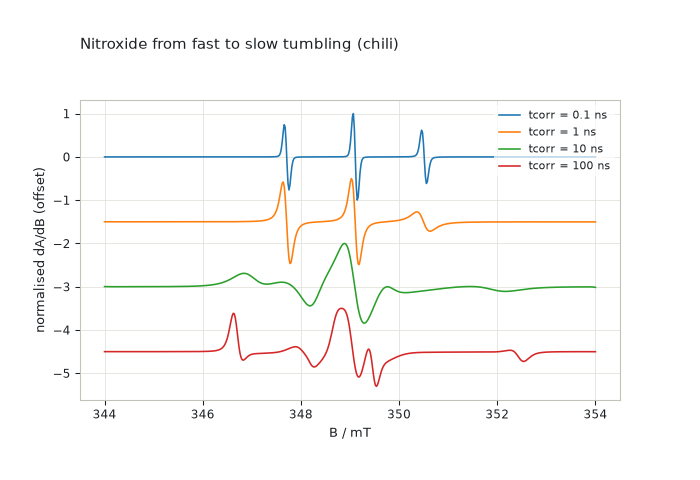

In [16]:
import plotly.graph_objects as go

fig = go.Figure()
for k, (tc, s) in enumerate(spectra.items()):
    fig.add_trace(go.Scatter(x=s.x, y=s.spec / np.abs(s.spec).max() - 1.5 * k, mode="lines", name=f"tcorr = {tc * 1e9:g} ns"))
fig.update_layout(title="Nitroxide from fast to slow tumbling (chili)", xaxis_title="B / mT", yaxis_title="normalised dA/dB (offset)", width=700, height=480)
fig

In [17]:
momd = {"g": [2.008, 2.006, 2.003], "Nucs": "14N", "A": [20, 20, 85], "lw": 0.3, "tcorr": 1e-8, "Potential": [[2, 0, 0, 1]]}
restrained = es.chili(momd, {"mwFreq": 9.5, "CenterSweep": [338, 20], "nPoints": 300}, {"GridSize": 5, "LLMK": [8, 0, 2, 2]})
free = es.chili({k: v for k, v in momd.items() if k != "Potential"}, {"mwFreq": 9.5, "CenterSweep": [338, 20], "nPoints": 300}, {"LLMK": [8, 0, 2, 2]})
print("MOMD with an ordering potential: norm of the equilibrium vector", round(restrained.info["normPeq"], 4), " spectra differ by", f"{np.abs(restrained.spec / np.abs(restrained.spec).max() - free.spec / np.abs(free.spec).max()).max():.2f}")

MOMD with an ordering potential: norm of the equilibrium vector 1.0  spectra differ by 0.07


## Pulse EPR: `saffron`

`saffron(spin_system, exp, opt)` simulates the echo modulation of pulse
experiments on a spin system with one electron spin and any number of
nuclei, with EasySpin's fast engine: the pulses are ideal (infinitely short
and non-selective), the electron spin manifolds are found for every
orientation of the grid (analytically for S = 1/2 with weakly coupled nuclei,
by diagonalisation otherwise), the nuclear sub-Hamiltonians of the two
manifolds give the nuclear frequencies and the overlap matrix, and the
modulation of every coherence transfer pathway is accumulated in a frequency
histogram and transformed to the time domain (`Opt["TimeDomain"] = True`
evolves in time instead). `Exp["Sequence"]` names a predefined experiment
(`"2pESEEM"`, `"3pESEEM"`, `"4pESEEM"`, `"HYSCORE"`, `"MimsENDOR"`) with
`Exp["Field"]` (mT), `dt` and `nPoints` for the time axis and `tau`, `T`,
`t1`, `t2` for the fixed delays, or lists a custom sequence of pulses
(`{"Flip": angle, "Phase": phase}`, with `"tp"` for a real rectangular pulse
of finite length) alternating with delays in microseconds, whose
incrementation `Exp["Dim1"] = [["d2", dt]]` names the delays that step
along each dimension. `Exp["mwFreq"]` with `Exp["ExciteWidth"]` selects the
orientations the first pulse excites; `Sys["T1"]`, `Sys["T2"]` add
relaxation decays; `Opt["ProductRule"]` treats the nuclei in separate
subspaces; `Opt["Nuclei"]` picks the nuclei that modulate, the others stay in
the electron Hamiltonian. The result holds the time axis (a pair for 2-D
experiments), the complex modulation signal, and in `info` the processed
spectrum (`fd`, after decay and baseline correction, apodisation with
`Opt["Window"]` and zero filling) with its frequency axis.

In [18]:
weak_n14 = {"Nucs": "14N", "A": [-1, -1, 2], "Q": [-1, -1, 2]}
three_pulse = es.saffron(weak_n14, {"Field": 350, "Sequence": "3pESEEM", "dt": 0.01, "nPoints": 512, "tau": 0.1})
hyscore = es.saffron(weak_n14, {"Field": 350, "Sequence": "HYSCORE", "dt": 0.02, "nPoints": 128, "tau": 0.1})
nu_n = es.larmorfrq("14N", 350)[0, 0]
print("time axis starts at tau + T =", three_pulse.x[0], "us; nuclear Larmor frequency", round(nu_n, 3), "MHz;",
      "HYSCORE spectrum", hyscore.info["fd"].shape, "on", round(hyscore.info["f1"][-1], 2), "MHz")

time axis starts at tau + T = 0.1 us; nuclear Larmor frequency 1.077 MHz; HYSCORE spectrum (256, 256) on 24.8 MHz


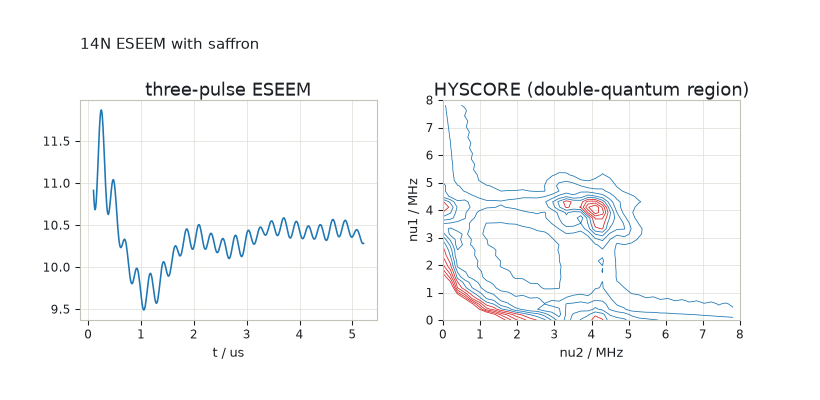

In [19]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=2, subplot_titles=("three-pulse ESEEM", "HYSCORE (double-quantum region)"))
fig.add_trace(go.Scatter(x=three_pulse.x, y=np.real(three_pulse.spec), mode="lines", name="echo modulation"), row=1, col=1)
f1, f2 = hyscore.info["f1"], hyscore.info["f2"]
win1, win2 = (f1 >= 0) & (f1 <= 8), (f2 >= 0) & (f2 <= 8)  # the plotted window only keeps the notebook small
f1, f2, z = f1[win1], f2[win2], np.abs(hyscore.info["fd"])[np.ix_(win1, win2)]
top = z[(f1 > 1.5)[:, None] & (f2 > 1.5)[None, :]].max()  # levels relative to the peaks away from the low-frequency corner
fig.add_trace(go.Contour(x=f2, y=f1, z=z, contours={"coloring": "lines", "start": 0.1 * top, "end": top, "size": 0.1 * top}, colorscale=[[0, "#1f77b4"], [1, "#d62728"]], showscale=False, name="|FT|"), row=1, col=2)
fig.update_xaxes(title_text="t / us", row=1, col=1)
fig.update_xaxes(title_text="nu2 / MHz", range=[0, 8], row=1, col=2)
fig.update_yaxes(title_text="nu1 / MHz", range=[0, 8], row=1, col=2)
fig.update_layout(title="14N ESEEM with saffron", width=820, height=400)
fig

In [20]:
mims = es.saffron({"Nucs": "1H", "A": [1, 1, 5], "lwEndor": 0.1}, {"Sequence": "MimsENDOR", "Field": 325, "tau": 0.1, "Range": [5, 25], "nPoints": 401})
custom = es.saffron(weak_n14, {"Field": 350, "Sequence": [{"Flip": np.pi / 2}, 0.1, {"Flip": np.pi / 2}, 0.0, {"Flip": np.pi / 2}, 0.1], "nPoints": 512, "Dim1": [["d2", 0.01]]})
print("Mims ENDOR doublet at", np.round(mims.x[np.argsort(mims.spec)[-1]], 2), "MHz;",
      "the custom three-pulse sequence reproduces the predefined one to", f"{np.abs(custom.spec - three_pulse.spec).max():.1e}")

Mims ENDOR doublet at 15.95 MHz; the custom three-pulse sequence reproduces the predefined one to 5.3e-15
